# Predicting Sri Lankan House Prices with Ensemble Learning

This notebook predicts the asking price of houses advertised on **ikman.lk**, Sri Lanka's largest classifieds site. The data is a public Kaggle dataset of scraped ikman.lk property ads (Kaggle link: *add link here*).

The same cleaned data is used to compare three ensemble ideas:

- **Bagging**: Random Forest (section 13)
- **Boosting**: XGBoost and CatBoost (section 14)
- **Stacking**: Random Forest, XGBoost and CatBoost, combined by a Ridge meta-model (section 16)

There is also a **hybrid** that blends a bagging model (Random Forest) with a boosting model (CatBoost) (section 15). All results, including an overfitting check, are in section 17. The final stacked model is saved and used by a Streamlit dashboard.

## 1. Load the ikman.lk data
About 204k property ads scraped from ikman.lk (Kaggle dataset). All libraries are imported here, then the CSV is loaded and its size and column types are checked.

In [119]:
import ast
import re
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=UserWarning)

df = pd.read_csv("./properties.csv")

In [120]:
df.head()

,ad_title,ad_description,details,slug,title,type,price,timestamp,posted_date,deactivation_date,...,is_doorstep_delivery,is_dsd_applicable,is_member,is_authorized_dealer,is_featured_member,is_verified,membership_level,member_since,properties,user
0,apartment for sale in colombo 05 | ikman,Project: Aquaria by Access Residencies.\n\nSq....,"Bedrooms: 3, Bathrooms: 2",apartment-for-sale-in-colombo-05-for-sale-colo...,apartment for sale in colombo 05,for_sale,"Rs 59,500,000",16 Feb 2:38 pm,2023-02-16T14:38:34+05:30,2022-01-31T04:43:32.000Z,...,False,False,True,False,False,True,plus,October 2016,"{'Address': 'kirimandala mawatha, colombo 05.'...",2a36021370cdd0f50da19f64d17ad43be687d48568ec12...
1,Land for Sale in Kurunegala | ikman.lk,à·à·à¶à·âà¶»à¶ºà·à¶±à· à¶¯à·à¶ºà·à¶«...,15.0 perches,land-for-sale-in-kurunegala-for-sale-kurunegal...,Land for Sale in Kurunegala,for_sale,"Rs 50,000 per perch",10 Nov 12:06 pm,2022-11-10T12:06:19+05:30,2022-07-30T09:30:41.000Z,...,False,False,True,False,False,False,premium,April 2017,"{'Address': 'kurunegala,malkaduwawa', 'Land ty...",f917ed789e936ada5530694ede4edde85fdb53f739c5f6...
2,Land for Sale in Kelaniya | ikman,Good Residential Bare Land in Kelaniya\nLocate...,18.5 perches,land-for-sale-in-kelaniya-for-sale-gampaha-766,Land for Sale in Kelaniya,for_sale,"Rs 1,600,000 per perch",30 Jan 8:54 am,2023-01-30T08:54:35+05:30,2022-07-30T09:31:26.000Z,...,False,False,True,False,False,True,premium,August 2016,"{'Address': 'Dalugama, Kelaniya', 'Land type':...",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254...
3,Land for Sale in Kelaniya | ikman,Good Residential bare land in Kelaniya\nLocate...,12.0 perches,land-for-sale-in-kelaniya-for-sale-gampaha-765,Land for Sale in Kelaniya,for_sale,"Rs 1,700,000 per perch",30 Jan 8:54 am,2023-01-30T08:54:29+05:30,2022-07-30T09:24:20.000Z,...,False,False,True,False,False,True,premium,August 2016,"{'Address': 'Off Kohalwila Road, Dalugama - Ke...",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254...
4,Semi Luxury House for Sale in Kadawatha | ikman,Semi Luxury House in Kadawatha\nLocated at Pin...,"Bedrooms: 5, Bathrooms: 4",semi-luxury-house-for-sale-in-kadawatha-for-sa...,Semi Luxury House for Sale in Kadawatha,for_sale,"Rs 55,000,000",30 Jan 8:54 am,2023-01-30T08:54:09+05:30,2021-10-03T08:33:36.000Z,...,False,False,True,False,False,True,premium,August 2016,"{'Address': 'Pinthaliya Road, Kadawatha', 'Bed...",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254...


In [121]:
df.shape

(203874, 26)

In [122]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 203874 entries, 0 to 203873
Data columns (total 26 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   ad_title              203874 non-null  str   
 1   ad_description        203872 non-null  str   
 2   details               202347 non-null  str   
 3   slug                  203874 non-null  str   
 4   title                 203874 non-null  str   
 5   type                  203874 non-null  str   
 6   price                 202312 non-null  str   
 7   timestamp             203868 non-null  str   
 8   posted_date           203868 non-null  str   
 9   deactivation_date     203868 non-null  str   
 10  category              203874 non-null  str   
 11  parent_category       203874 non-null  str   
 12  location              203874 non-null  str   
 13  geo_region            203874 non-null  str   
 14  area                  203874 non-null  str   
 15  is_delivery_free      203874

### 1.1 Missing values and ad categories
Which columns have gaps, and how the ads split across property types.

In [123]:
print(df.columns.tolist())

['ad_title', 'ad_description', 'details', 'slug', 'title', 'type', 'price', 'timestamp', 'posted_date', 'deactivation_date', 'category', 'parent_category', 'location', 'geo_region', 'area', 'is_delivery_free', 'is_doorstep_delivery', 'is_dsd_applicable', 'is_member', 'is_authorized_dealer', 'is_featured_member', 'is_verified', 'membership_level', 'member_since', 'properties', 'user']


In [124]:
display(df.isnull().sum())

ad_title                    0
ad_description              2
details                  1527
slug                        0
title                       0
type                        0
price                    1562
timestamp                   6
posted_date                 6
deactivation_date           6
category                    0
parent_category             0
location                    0
geo_region                  0
area                        0
is_delivery_free            0
is_doorstep_delivery        0
is_dsd_applicable           0
is_member                4462
is_authorized_dealer     4462
is_featured_member       4462
is_verified                 0
membership_level            0
member_since            26459
properties                  0
user                        0
dtype: int64

In [125]:
display(df["category"].value_counts())

category
Land For Sale                     82324
Houses For Sale                   52193
Land                              27155
House Rentals                     15179
Apartment Rentals                  7221
Apartments For Sale                5198
Room & Annex Rentals               4609
Commercial Property Rentals        4541
Commercial Properties For Sale     2752
Holiday & Short-Term Rental        2533
Land Rentals                        134
New Projects                         35
Name: count, dtype: int64

## 2. Keep only houses for sale
Land, rentals and apartments are priced very differently, so only "Houses For Sale" ads are kept (about 51.9k rows).

In [126]:
house_df = df[
    (df["category"] == "Houses For Sale") &
    (df["type"] == "for_sale")
].copy()

print("Remaining rows:", len(house_df))

Remaining rows: 51890


## 3. Clean the price
Prices are stored as text like "Rs 55,000,000". The number is pulled out and ads without a usable price are dropped.

In [127]:
house_df["price_lkr"] = pd.to_numeric(
    house_df["price"]
    .str.extract(r"Rs\s*([\d,]+(?:\.\d+)?)")[0]
    .str.replace(",", "", regex=False),
    errors="coerce"
)

house_df[["price", "price_lkr"]].head()

,price,price_lkr
4,"Rs 55,000,000",55000000.0
9,"Rs 80,000,000",80000000.0
21,"Rs 125,000,000",125000000.0
22,"Rs 58,000,000",58000000.0
24,"Rs 22,000,000",22000000.0


In [128]:
house_df = house_df.dropna(subset=["price_lkr"])

## 4. Extract features from the properties field
The `properties` column is a dictionary saved as text. It is parsed to get bedrooms, bathrooms and house size (sqft).

In [129]:
house_df.head()

,ad_title,ad_description,details,slug,title,type,price,timestamp,posted_date,deactivation_date,...,is_dsd_applicable,is_member,is_authorized_dealer,is_featured_member,is_verified,membership_level,member_since,properties,user,price_lkr
4,Semi Luxury House for Sale in Kadawatha | ikman,Semi Luxury House in Kadawatha\nLocated at Pin...,"Bedrooms: 5, Bathrooms: 4",semi-luxury-house-for-sale-in-kadawatha-for-sa...,Semi Luxury House for Sale in Kadawatha,for_sale,"Rs 55,000,000",30 Jan 8:54 am,2023-01-30T08:54:09+05:30,2021-10-03T08:33:36.000Z,...,False,True,False,False,True,premium,August 2016,"{'Address': 'Pinthaliya Road, Kadawatha', 'Bed...",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254...,55000000.0
9,Two Story House for Sale in Dehiwela | ikman,Kadawatha Road Dehiwala \n4 bedrooms 4 bathroo...,"Bedrooms: 4, Bathrooms: 4",two-story-house-for-sale-in-dehiwela-for-sale-...,Two Story House for Sale in Dehiwela,for_sale,"Rs 80,000,000",14 Feb 10:31 pm,2023-02-14T22:31:10+05:30,2022-01-30T17:38:24.000Z,...,False,True,False,False,True,premium,February 2021,"{'Address': 'kadawatha Road', 'Bedrooms': '4',...",765b8447b8c0b5fd5027da030129879e06ca0e744dc8da...,80000000.0
21,House for Sale in Mount Lavinia | ikman,A Two-story British style house for sale in Mo...,"Bedrooms: 4, Bathrooms: 2",house-for-sale-in-mount-lavinia-for-sale-colom...,House for Sale in Mount Lavinia,for_sale,"Rs 125,000,000",30 Jan 8:54 am,2023-01-30T08:54:39+05:30,2022-07-30T10:15:29.000Z,...,False,True,False,False,True,premium,August 2016,"{'Address': 'Off Temple Road, Mount Lavinia', ...",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254...,125000000.0
22,Luxurious House for sale in Hokandara Malabe |...,Description\n\nLuxury Villa for sale in Hokand...,"Bedrooms: 4, Bathrooms: 3",luxurious-house-for-sale-in-hokandara-malabe-f...,Luxurious House for sale in Hokandara Malabe,for_sale,"Rs 58,000,000",07 Jan 12:01 pm,2023-01-07T12:01:31+05:30,2022-05-30T05:44:29.000Z,...,False,True,False,False,True,premium,January 2017,"{'Bedrooms': '4', 'Bathrooms': '3', 'House siz...",1055f51db0e8b8f4b78aae48f33af949247549d7088037...,58000000.0
24,Uncompleted House for Sale in Kotte | ikman.lk,Uncompleted HOUSE FOR SALE IN Kotte ðï¸\n\...,"Bedrooms: 4, Bathrooms: 3",uncompleted-house-for-sale-in-kotte-for-sale-c...,Uncompleted House for Sale in Kotte,for_sale,"Rs 22,000,000",30 Oct 1:44 pm,2022-10-30T13:44:14+05:30,2022-07-29T12:01:42.000Z,...,False,True,False,False,False,premium,January 2019,"{'Address': 'Kotte', 'Bedrooms': '4', 'Bathroo...",9a3fb9c590d014047dff6a0c8337c6038670c47277a79c...,22000000.0


In [130]:
# Safely convert dictionary-like text into dictionaries
def parse_dict(value):
    try:
        result = ast.literal_eval(value)
        return result if isinstance(result, dict) else {}
    except (ValueError, SyntaxError, TypeError):
        return {}

house_df["property_dict"] = house_df["properties"].apply(parse_dict)

# Extract numeric part from a value
def extract_number(value):
    if pd.isna(value):
        return np.nan

    match = re.search(r"\d[\d,]*(?:\.\d+)?", str(value))

    if match:
        return float(match.group().replace(",", ""))

    return np.nan

house_df["bedrooms"] = house_df["property_dict"].apply(
    lambda x: extract_number(x.get("Bedrooms"))
)

house_df["bathrooms"] = house_df["property_dict"].apply(
    lambda x: extract_number(x.get("Bathrooms"))
)

house_df["house_sqft"] = house_df["property_dict"].apply(
    lambda x: extract_number(x.get("House size"))
)

### 4.1 Land size in perches
Land is listed in perches or acres, so everything is converted to perches (1 acre = 160 perches).

In [131]:
def convert_land_to_perches(value):
    number = extract_number(value)

    if pd.isna(number):
        return np.nan

    text = str(value).lower()

    if "acre" in text:
        return number * 160

    if "perch" in text:
        return number

    return np.nan

house_df["land_perches"] = house_df["property_dict"].apply(
    lambda x: convert_land_to_perches(x.get("Land size"))
)

## 5. District and town
The district comes from the `area` field and the town from `location`.

In [132]:
house_df["district"] = house_df["area"].apply(
    lambda x: parse_dict(x).get("name")
)

house_df[["district", "location"]].head()

,district,location
4,Gampaha,Kadawatha
9,Colombo,Dehiwala
21,Colombo,Mount Lavinia
22,Colombo,Malabe
24,Colombo,Kotte


## 6. Missing values and summary stats
Prices run from Rs 7 to Rs 900 billion, so there are clear typos to clean before modelling.

In [133]:
features = [
    "price_lkr",
    "bedrooms",
    "bathrooms",
    "house_sqft",
    "land_perches",
    "district",
    "location"
]

display(house_df[features].isnull().sum())
display(house_df[features].describe())

price_lkr       0
bedrooms        0
bathrooms       0
house_sqft      0
land_perches    0
district        0
location        0
dtype: int64

,price_lkr,bedrooms,bathrooms,house_sqft,land_perches
count,5.188800e+04,51888.000000,51888.000000,51888.000000,51888.000000
mean,5.838041e+07,3.783823,2.732539,2670.177824,19.388779
std,3.951135e+09,1.245805,1.341207,5612.087094,341.239342
min,7.000000e+00,1.000000,1.000000,0.000000,0.000000
25%,1.700000e+07,3.000000,2.000000,1525.000000,7.360000
50%,2.850000e+07,4.000000,3.000000,2350.000000,10.000000
75%,4.750000e+07,4.000000,4.000000,3200.000000,12.500000
max,9.000000e+11,10.000000,10.000000,900000.000000,62500.000000


## 7. Outliers
Boxplots of house size and land size show a long tail of unrealistic values.

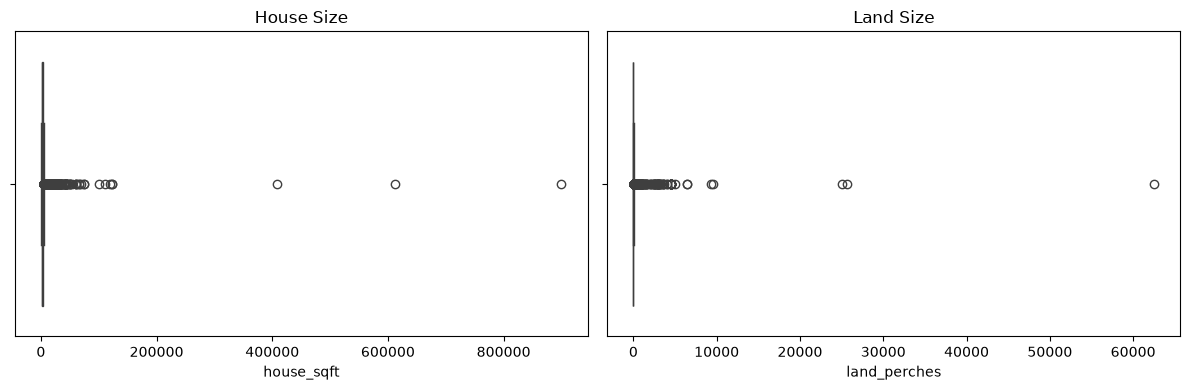

In [134]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=house_df["house_sqft"], ax=axes[0])
axes[0].set_title("House Size")

sns.boxplot(x=house_df["land_perches"], ax=axes[1])
axes[1].set_title("Land Size")

plt.tight_layout()
plt.show()

### 7.1 Remove unrealistic listings
Keep prices between Rs 1M and 500M, houses of 300 to 20,000 sqft and land of 1 to 500 perches. Rows missing key fields are dropped.

In [135]:
# Parse dates before final cleaning
house_df["posted_date"] = pd.to_datetime(
    house_df["posted_date"],
    errors="coerce",
    utc=True
)

house_df = house_df[
    house_df["price_lkr"].between(1_000_000, 500_000_000) &
    house_df["house_sqft"].between(300, 20_000) &
    house_df["land_perches"].between(1, 500)
].copy()

house_df = house_df.dropna(
    subset=["posted_date", "district", "location",
            "bedrooms", "bathrooms"]
)

print("Remaining records:", len(house_df))

Remaining records: 51378


In [136]:
house_df.head()

,ad_title,ad_description,details,slug,title,type,price,timestamp,posted_date,deactivation_date,...,member_since,properties,user,price_lkr,property_dict,bedrooms,bathrooms,house_sqft,land_perches,district
4,Semi Luxury House for Sale in Kadawatha | ikman,Semi Luxury House in Kadawatha\nLocated at Pin...,"Bedrooms: 5, Bathrooms: 4",semi-luxury-house-for-sale-in-kadawatha-for-sa...,Semi Luxury House for Sale in Kadawatha,for_sale,"Rs 55,000,000",30 Jan 8:54 am,2023-01-30 03:24:09+00:00,2021-10-03T08:33:36.000Z,...,August 2016,"{'Address': 'Pinthaliya Road, Kadawatha', 'Bed...",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254...,55000000.0,"{'Address': 'Pinthaliya Road, Kadawatha', 'Bed...",5.0,4.0,3000.0,27.50,Gampaha
9,Two Story House for Sale in Dehiwela | ikman,Kadawatha Road Dehiwala \n4 bedrooms 4 bathroo...,"Bedrooms: 4, Bathrooms: 4",two-story-house-for-sale-in-dehiwela-for-sale-...,Two Story House for Sale in Dehiwela,for_sale,"Rs 80,000,000",14 Feb 10:31 pm,2023-02-14 17:01:10+00:00,2022-01-30T17:38:24.000Z,...,February 2021,"{'Address': 'kadawatha Road', 'Bedrooms': '4',...",765b8447b8c0b5fd5027da030129879e06ca0e744dc8da...,80000000.0,"{'Address': 'kadawatha Road', 'Bedrooms': '4',...",4.0,4.0,3000.0,8.75,Colombo
21,House for Sale in Mount Lavinia | ikman,A Two-story British style house for sale in Mo...,"Bedrooms: 4, Bathrooms: 2",house-for-sale-in-mount-lavinia-for-sale-colom...,House for Sale in Mount Lavinia,for_sale,"Rs 125,000,000",30 Jan 8:54 am,2023-01-30 03:24:39+00:00,2022-07-30T10:15:29.000Z,...,August 2016,"{'Address': 'Off Temple Road, Mount Lavinia', ...",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254...,125000000.0,"{'Address': 'Off Temple Road, Mount Lavinia', ...",4.0,2.0,5600.0,20.00,Colombo
22,Luxurious House for sale in Hokandara Malabe |...,Description\n\nLuxury Villa for sale in Hokand...,"Bedrooms: 4, Bathrooms: 3",luxurious-house-for-sale-in-hokandara-malabe-f...,Luxurious House for sale in Hokandara Malabe,for_sale,"Rs 58,000,000",07 Jan 12:01 pm,2023-01-07 06:31:31+00:00,2022-05-30T05:44:29.000Z,...,January 2017,"{'Bedrooms': '4', 'Bathrooms': '3', 'House siz...",1055f51db0e8b8f4b78aae48f33af949247549d7088037...,58000000.0,"{'Bedrooms': '4', 'Bathrooms': '3', 'House siz...",4.0,3.0,4000.0,16.00,Colombo
24,Uncompleted House for Sale in Kotte | ikman.lk,Uncompleted HOUSE FOR SALE IN Kotte ðï¸\n\...,"Bedrooms: 4, Bathrooms: 3",uncompleted-house-for-sale-in-kotte-for-sale-c...,Uncompleted House for Sale in Kotte,for_sale,"Rs 22,000,000",30 Oct 1:44 pm,2022-10-30 08:14:14+00:00,2022-07-29T12:01:42.000Z,...,January 2019,"{'Address': 'Kotte', 'Bedrooms': '4', 'Bathroo...",9a3fb9c590d014047dff6a0c8337c6038670c47277a79c...,22000000.0,"{'Address': 'Kotte', 'Bedrooms': '4', 'Bathroo...",4.0,3.0,2200.0,6.50,Colombo


## 8. Remove reposted ads
Sellers often repost the same house. If copies end up in both train and test, the scores look better than they really are, so only the first post is kept (51.4k down to 36.6k).

In [137]:
# Sort by advertisement date
house_df = house_df.sort_values("posted_date")

# Identify likely reposted properties
duplicate_columns = [
    "user",
    "ad_description",
    "properties",
    "location"
]

house_df = house_df.drop_duplicates(
    subset=duplicate_columns,
    keep="first"
)

print("Records after deduplication:", len(house_df))

Records after deduplication: 36642


## 9. Final modelling table
Posting date, location, size features and the price.

In [138]:
model_df = house_df[
    [
        "posted_date",
        "district",
        "location",
        "bedrooms",
        "bathrooms",
        "house_sqft",
        "land_perches",
        "price_lkr"
    ]
].copy()

display(model_df.head())

,posted_date,district,location,bedrooms,bathrooms,house_sqft,land_perches,price_lkr
4163,2022-09-08 06:49:41+00:00,Gampaha,Ja-Ela,3.0,2.0,1425.0,9.0,17500000.0
4179,2022-09-09 15:55:42+00:00,Kurunegala,Polgahawela,2.0,1.0,850.0,18.0,4500000.0
4564,2022-09-12 12:45:49+00:00,Gampaha,Kadawatha,4.0,3.0,3356.0,15.0,47500000.0
4628,2022-09-14 01:46:16+00:00,Colombo,Piliyandala,3.0,2.0,1100.0,7.5,14000000.0
5175,2022-09-21 04:07:34+00:00,Gampaha,Kiribathgoda,3.0,3.0,1600.0,15.0,22750000.0


## 10. Exploratory analysis
Prices are converted to LKR millions so the plots are easier to read.

In [139]:
eda_df = model_df.copy()

# Create price in millions for easier visualization
eda_df["price_million"] = (
    eda_df["price_lkr"] / 1_000_000
)

display(eda_df.head())
print(eda_df.shape)

,posted_date,district,location,bedrooms,bathrooms,house_sqft,land_perches,price_lkr,price_million
4163,2022-09-08 06:49:41+00:00,Gampaha,Ja-Ela,3.0,2.0,1425.0,9.0,17500000.0,17.50
4179,2022-09-09 15:55:42+00:00,Kurunegala,Polgahawela,2.0,1.0,850.0,18.0,4500000.0,4.50
4564,2022-09-12 12:45:49+00:00,Gampaha,Kadawatha,4.0,3.0,3356.0,15.0,47500000.0,47.50
4628,2022-09-14 01:46:16+00:00,Colombo,Piliyandala,3.0,2.0,1100.0,7.5,14000000.0,14.00
5175,2022-09-21 04:07:34+00:00,Gampaha,Kiribathgoda,3.0,3.0,1600.0,15.0,22750000.0,22.75


(36642, 9)


### 10.1 Price distribution
Most houses are under Rs 50M, with a long right tail of luxury homes.

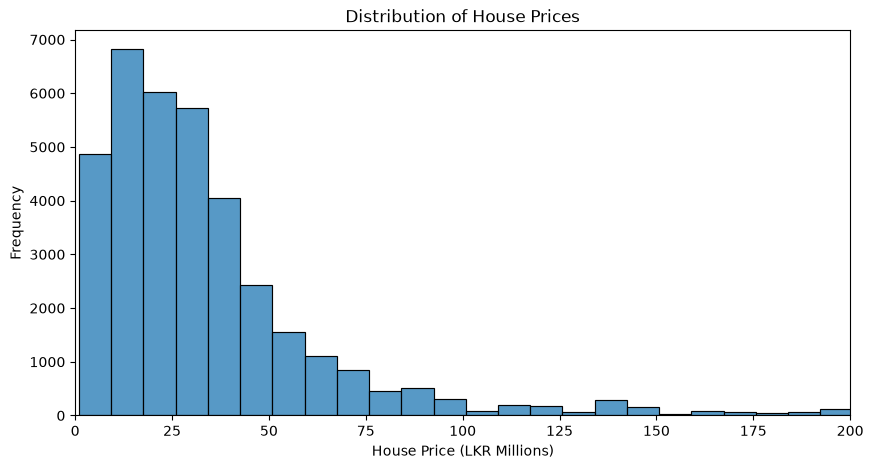

In [140]:
plt.figure(figsize=(10, 5))

sns.histplot(
    eda_df["price_million"],
    bins=60
)

plt.xlim(0, 200)
plt.xlabel("House Price (LKR Millions)")
plt.ylabel("Frequency")
plt.title("Distribution of House Prices")

plt.show()

### 10.2 House size vs price
A random sample of 5,000 ads is plotted so the points don't pile on top of each other.

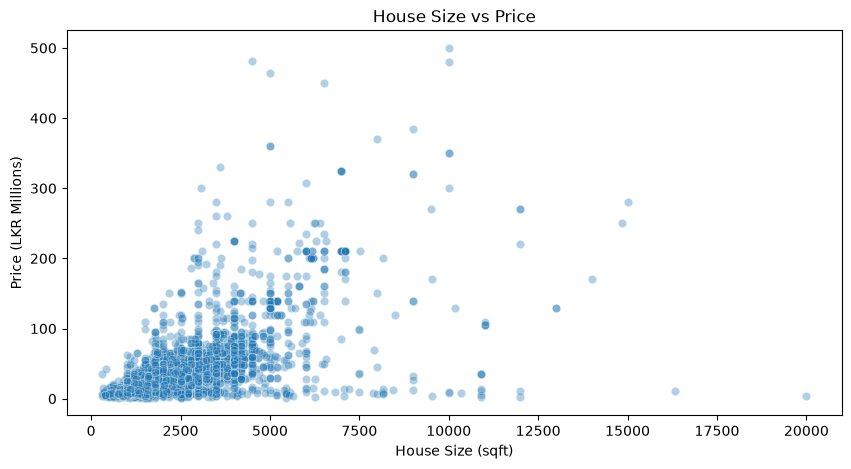

In [141]:
sample_df = eda_df.sample(
    n=min(5000, len(eda_df)),
    random_state=42
)

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=sample_df,
    x="house_sqft",
    y="price_million",
    alpha=0.35
)

plt.xlabel("House Size (sqft)")
plt.ylabel("Price (LKR Millions)")
plt.title("House Size vs Price")

plt.show()

### 10.3 Median price by district
Location matters a lot: Colombo and nearby districts sit well above the rest of the island.

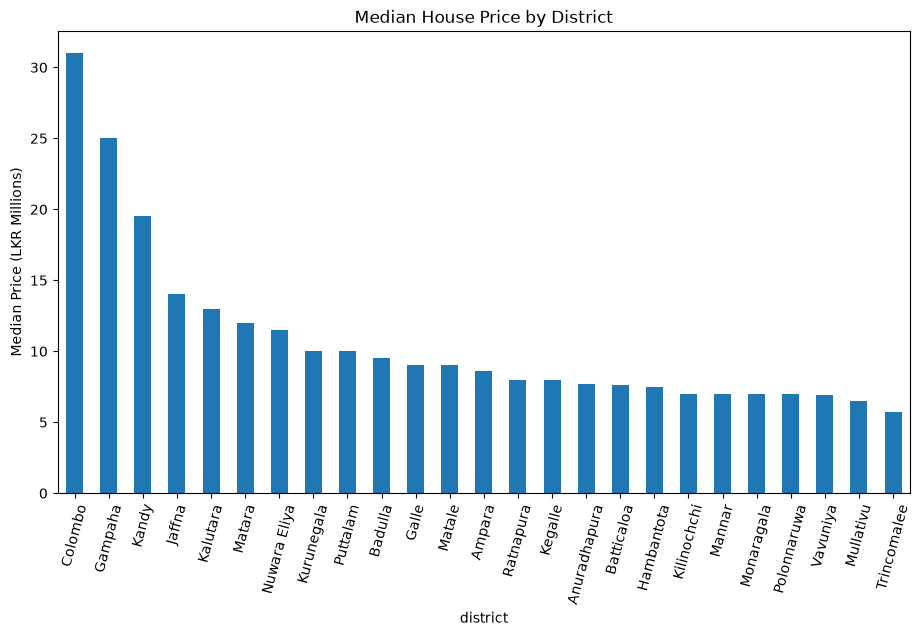

In [142]:
district_prices = (
    eda_df.groupby("district")["price_million"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 6))

district_prices.plot(kind="bar")

plt.ylabel("Median Price (LKR Millions)")
plt.title("Median House Price by District")
plt.xticks(rotation=75)

plt.show()

### 10.4 Correlation between numeric features
How strongly the size features move with each other and with price.

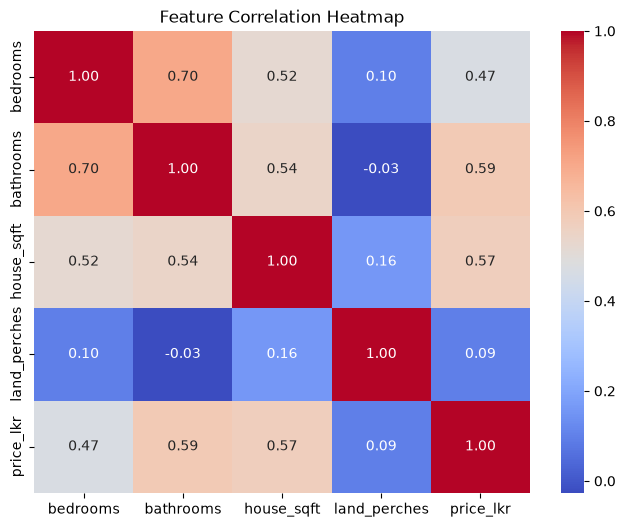

In [143]:
numeric_cols = [
    "bedrooms",
    "bathrooms",
    "house_sqft",
    "land_perches",
    "price_lkr"
]

plt.figure(figsize=(8, 6))

sns.heatmap(
    eda_df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

## 11. Train/test split by date
Train on the oldest 80% of ads and test on the newest 20%. This mimics predicting prices for new listings and avoids peeking into the future.

In [144]:
# Sort cleaned dataset chronologically
model_df = model_df.sort_values(
    "posted_date"
).reset_index(drop=True)

# Input features
feature_cols = [
    "district",
    "location",
    "bedrooms",
    "bathrooms",
    "house_sqft",
    "land_perches"
]

# 80% training, 20% testing
split_index = int(len(model_df) * 0.8)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

# Features
X_train = train_df[feature_cols]
X_test = test_df[feature_cols]

# Target in millions of LKR
y_train = train_df["price_lkr"] / 1_000_000
y_test = test_df["price_lkr"] / 1_000_000

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (29313, 6)
Testing: (7329, 6)


## 12. Preprocessing
Numeric columns get a median fill. District and town get a most-frequent fill and one-hot encoding, and towns with fewer than 80 ads are grouped as "infrequent". Tree models don't need scaling, so nothing else is done to the numbers.

In [145]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_features = [
    "bedrooms",
    "bathrooms",
    "house_sqft",
    "land_perches"
]

categorical_features = [
    "district",
    "location"
]

def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median"
        ))
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="most_frequent"
        )),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=80
        ))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

# Test-set predictions and training times, filled in as each model is trained
predictions = {}
train_times = {}

In [146]:
X_train.head()

,district,location,bedrooms,bathrooms,house_sqft,land_perches
0,Gampaha,Ja-Ela,3.0,2.0,1425.0,9.0
1,Kurunegala,Polgahawela,2.0,1.0,850.0,18.0
2,Gampaha,Kadawatha,4.0,3.0,3356.0,15.0
3,Colombo,Piliyandala,3.0,2.0,1100.0,7.5
4,Gampaha,Kiribathgoda,3.0,3.0,1600.0,15.0


## 13. Bagging: Random Forest
**This is where bagging happens.** Each of the 60 trees learns from a bootstrap sample of the rows (drawn with replacement) and a random 65% of the features at each split. The final price is the average of all trees. Averaging many noisy trees mainly reduces **variance**.

In [147]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", RandomForestRegressor(
        n_estimators=60,
        max_depth=12,
        min_samples_leaf=4,
        max_features=0.65,
        random_state=42,
        n_jobs=4
    ))
])

start = time.time()
rf_pipeline.fit(X_train, y_train)
train_times["Random Forest"] = time.time() - start

rf_predictions = rf_pipeline.predict(X_test)
predictions["Random Forest"] = rf_predictions

## 14. Boosting: XGBoost
**This is where boosting happens.** Trees are built one after another, and each new tree is fitted to the errors the previous trees still make. The small learning rate (0.05) keeps each step careful. Boosting mainly reduces **bias**.

In [148]:
from xgboost import XGBRegressor

xgb_pipeline = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", XGBRegressor(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=2.0,
        tree_method="hist",
        random_state=42,
        n_jobs=4
    ))
])

start = time.time()
xgb_pipeline.fit(X_train, y_train)
train_times["XGBoost"] = time.time() - start

xgb_predictions = xgb_pipeline.predict(X_test)
predictions["XGBoost"] = xgb_predictions

### 14.1 Boosting: CatBoost
CatBoost is another gradient boosting library. It builds symmetric (balanced) trees and uses ordered boosting, which helps against overfitting. It gets the same one-hot preprocessing as XGBoost, so it can be reused in the hybrid and the stack.

In [149]:
from catboost import CatBoostRegressor

cat_pipeline = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", CatBoostRegressor(
        iterations=800,
        depth=6,
        learning_rate=0.05,
        l2_leaf_reg=3,
        random_seed=42,
        thread_count=4,
        verbose=0
    ))
])

start = time.time()
cat_pipeline.fit(X_train, y_train)
train_times["CatBoost"] = time.time() - start

cat_predictions = cat_pipeline.predict(X_test)
predictions["CatBoost"] = cat_predictions

## 15. Hybrid: Random Forest + CatBoost
**This is the hybridization step.** It takes a weighted average of a bagging model (Random Forest, low variance) and a boosting model (CatBoost, low bias). The weight is chosen on the newest 20% of the *training* data, never on the test set.

Best blend: 0.35 x Random Forest + 0.65 x CatBoost


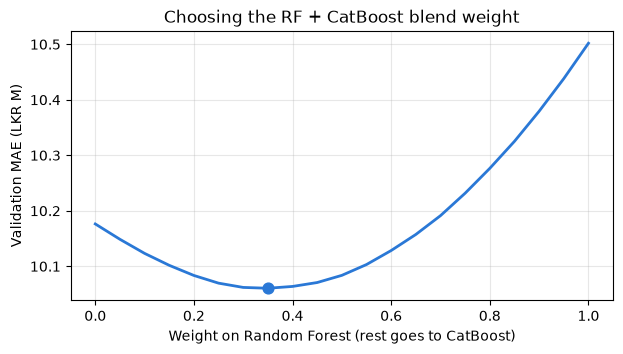

In [150]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error

val_split = int(len(X_train) * 0.8)
X_fit, X_val = X_train.iloc[:val_split], X_train.iloc[val_split:]
y_fit, y_val = y_train.iloc[:val_split], y_train.iloc[val_split:]

rf_val = clone(rf_pipeline).fit(X_fit, y_fit).predict(X_val)
cat_val = clone(cat_pipeline).fit(X_fit, y_fit).predict(X_val)

weights = np.linspace(0, 1, 21)
val_mae = [
    mean_absolute_error(y_val, w * rf_val + (1 - w) * cat_val)
    for w in weights
]
best_w = float(weights[int(np.argmin(val_mae))])
print(f"Best blend: {best_w:.2f} x Random Forest + {1 - best_w:.2f} x CatBoost")

hybrid_predictions = best_w * rf_predictions + (1 - best_w) * cat_predictions
predictions["Hybrid RF + CatBoost"] = hybrid_predictions
train_times["Hybrid RF + CatBoost"] = train_times["Random Forest"] + train_times["CatBoost"]

plt.figure(figsize=(7, 3.5))
plt.plot(weights, val_mae, color="#2a78d6", linewidth=2)
plt.scatter([best_w], [min(val_mae)], color="#2a78d6", s=60, zorder=3)
plt.xlabel("Weight on Random Forest (rest goes to CatBoost)")
plt.ylabel("Validation MAE (LKR M)")
plt.title("Choosing the RF + CatBoost blend weight")
plt.grid(alpha=0.3)
plt.show()

## 16. Stacking
**This is where stacking happens.** Random Forest (bagging), XGBoost and CatBoost (boosting) are the base models. Using 5-fold cross-validation, each base model predicts rows it wasn't trained on, and a Ridge regression learns from those predictions how much to trust each model. Ridge is limited to positive weights so they're easy to read.

In [151]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold

stack_model = StackingRegressor(
    estimators=[
        ("Random Forest", rf_pipeline),
        ("XGBoost", xgb_pipeline),
        ("CatBoost", cat_pipeline)
    ],
    final_estimator=Ridge(alpha=1.0, positive=True),
    cv=KFold(n_splits=5),
    n_jobs=1
)

start = time.time()
stack_model.fit(X_train, y_train)
train_times["Stacking"] = time.time() - start

stack_predictions = stack_model.predict(X_test)
predictions["Stacking"] = stack_predictions

### 16.1 What the meta-model learned
The Ridge weights show how much each base model contributes to the final price.

In [152]:
stack_weights = pd.Series(
    stack_model.final_estimator_.coef_,
    index=[name for name, _ in stack_model.estimators],
    name="Weight"
)

display(stack_weights.round(3).to_frame())
print("Intercept:", round(float(stack_model.final_estimator_.intercept_), 3))

,Weight
Random Forest,0.126
XGBoost,0.141
CatBoost,0.775


Intercept: -1.445


## 17. Results and overfitting check
All models in one table, scored on the training data and on the newest 20% of ads (test):
- **MAE**: average error in LKR millions
- **RMSE**: like MAE, but punishes big misses more
- **R²**: share of price variation explained
- **Gap**: train R² minus test R². A big gap means the model memorised the training data (overfitting). Low scores on both sets mean it is too simple (underfitting).

Because the split is by date, part of the gap also comes from prices changing over time.

In [153]:
# Colours for model families (used in the comparison charts)
FAMILY_COLOURS = {
    "Baseline": "#898781",
    "Bagging": "#2a78d6",
    "Boosting": "#eb6834",
    "Hybrid": "#eda100",
    "Stacking": "#e87ba4",
}

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(y_true, preds):
    return {
        "MAE": mean_absolute_error(y_true, preds),
        "RMSE": np.sqrt(mean_squared_error(y_true, preds)),
        "R2": r2_score(y_true, preds)
    }

model_family = {
    "Median Baseline": "Baseline",
    "Random Forest": "Bagging",
    "XGBoost": "Boosting",
    "CatBoost": "Boosting",
    "Hybrid RF + CatBoost": "Hybrid",
    "Stacking": "Stacking"
}

# Test-set predictions (from the model cells above) plus the baseline
all_predictions = {
    "Median Baseline": np.full(len(y_test), y_train.median()),
    **predictions
}

# Training-set predictions for the overfitting check
rf_train = rf_pipeline.predict(X_train)
cat_train = cat_pipeline.predict(X_train)

train_predictions = {
    "Median Baseline": np.full(len(y_train), y_train.median()),
    "Random Forest": rf_train,
    "XGBoost": xgb_pipeline.predict(X_train),
    "CatBoost": cat_train,
    "Hybrid RF + CatBoost": best_w * rf_train + (1 - best_w) * cat_train,
    "Stacking": stack_model.predict(X_train)
}

rows = []
for name in all_predictions:
    train_scores = evaluate_model(y_train, train_predictions[name])
    test_scores = evaluate_model(y_test, all_predictions[name])
    gap = train_scores["R2"] - test_scores["R2"]
    rows.append({
        "Model": name,
        "Family": model_family[name],
        "Train R2": train_scores["R2"],
        "Test R2": test_scores["R2"],
        "Gap": gap,
        "Train MAE": train_scores["MAE"],
        "Test MAE": test_scores["MAE"],
        "Test RMSE": test_scores["RMSE"],
        "Train time (s)": train_times.get(name, 0.0)
    })

results = (
    pd.DataFrame(rows)
    .sort_values("Test R2", ascending=False)
    .reset_index(drop=True)
)

display(results.round(3))

,Model,Family,Train R2,Test R2,Gap,Train MAE,Test MAE,Test RMSE,Train time (s)
0,Hybrid RF + CatBoost,Hybrid,0.828,0.750,0.079,8.319,10.376,22.826,4.953
1,Stacking,Stacking,0.828,0.749,0.079,8.425,10.418,22.836,28.274
2,CatBoost,Boosting,0.825,0.746,0.079,8.568,10.520,22.992,2.627
3,XGBoost,Boosting,0.813,0.742,0.070,8.624,10.555,23.152,0.641
4,Random Forest,Bagging,0.813,0.730,0.083,8.474,10.796,23.692,2.326
5,Median Baseline,Baseline,-0.063,-0.077,0.014,22.032,24.432,47.332,0.000


### 17.1 Results chart
Left: train vs test R² for each model (solid = train, hatched = test). Right: test MAE (lower is better). The baseline is left out because its R² is about 0.

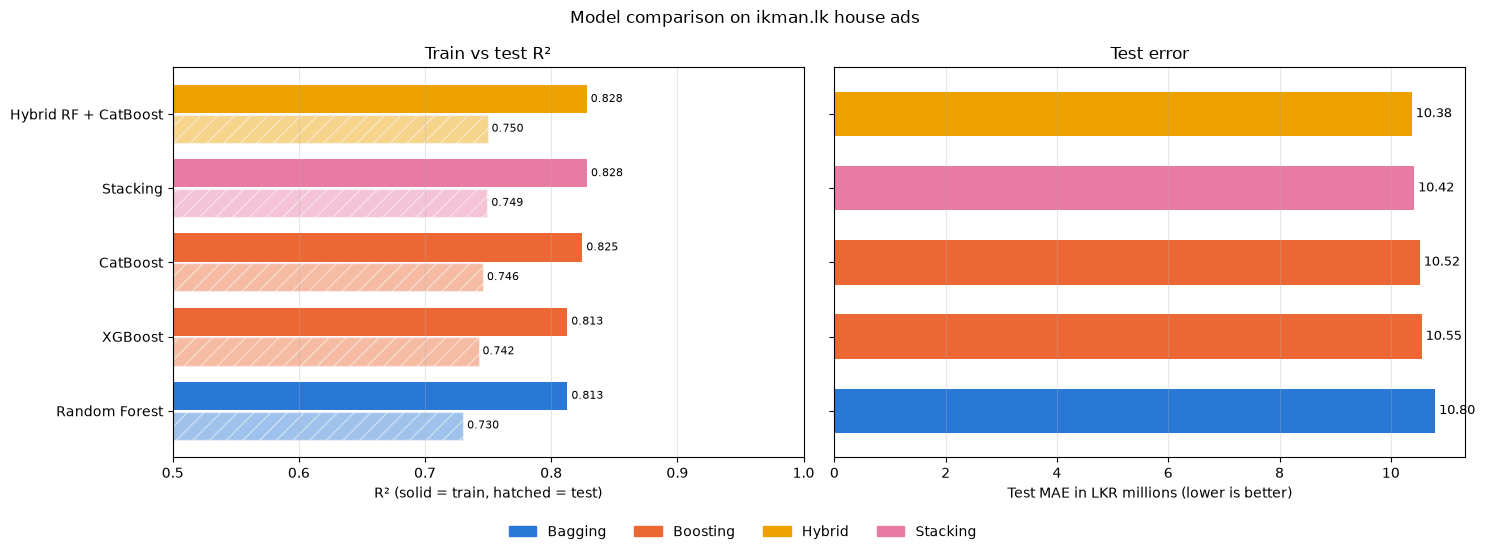

In [154]:
plot_df = results[results["Model"] != "Median Baseline"]
colours = plot_df["Family"].map(FAMILY_COLOURS)
y_pos = np.arange(len(plot_df))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)

ax = axes[0]
ax.barh(y_pos - 0.2, plot_df["Train R2"], height=0.38, color=colours)
ax.barh(y_pos + 0.2, plot_df["Test R2"], height=0.38, color=colours,
        alpha=0.45, hatch="//", edgecolor="white")
for y, (tr, te) in enumerate(zip(plot_df["Train R2"], plot_df["Test R2"])):
    ax.text(tr, y - 0.2, f" {tr:.3f}", va="center", fontsize=8)
    ax.text(te, y + 0.2, f" {te:.3f}", va="center", fontsize=8)
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("R² (solid = train, hatched = test)")
ax.set_title("Train vs test R²")

ax = axes[1]
ax.barh(y_pos, plot_df["Test MAE"], height=0.6, color=colours)
for y, v in enumerate(plot_df["Test MAE"]):
    ax.text(v, y, f" {v:.2f}", va="center", fontsize=9)
ax.set_xlabel("Test MAE in LKR millions (lower is better)")
ax.set_title("Test error")

axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(plot_df["Model"])
axes[0].invert_yaxis()
for ax in axes:
    ax.grid(axis="x", alpha=0.3)

families = [f for f in FAMILY_COLOURS if f in set(plot_df["Family"])]
handles = [plt.Rectangle((0, 0), 1, 1, color=FAMILY_COLOURS[f]) for f in families]
fig.legend(handles, families, loc="lower center", ncol=len(families), frameon=False)

plt.suptitle("Model comparison on ikman.lk house ads")
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

## 18. Interpretation

**Overall.** Every model beats the median baseline by a wide margin (test R² of -0.08 for the baseline vs 0.73 to 0.75 for the models). The models land close together, between test R² 0.730 and 0.750 and MAE Rs 10.4M to 10.8M. With only six inputs, the data itself sets a ceiling.

**Bagging (Random Forest) reduces variance.** Each of the 60 trees is trained on a different bootstrap sample, and averaging them smooths out the mistakes any single deep tree would make. The trees themselves don't get smarter, though. Bagging lowers variance, not bias, so Random Forest is the weakest of the ensembles here (test R² 0.730, MAE Rs 10.80M).

**Boosting reduces bias, so it beats bagging.** XGBoost (0.742) and CatBoost (0.746) both score higher than Random Forest. Price depends on combinations: a 2,500 sqft house in Colombo 7 and one in Kurunegala are worlds apart. Each boosting round fits a new tree to the errors that are left, so these interactions get learned step by step. CatBoost edges out XGBoost thanks to its balanced (symmetric) trees and ordered boosting, which also make it more stable.

**Hybrid: Random Forest + CatBoost.** The best blend on the validation data is 0.35 × RF + 0.65 × CatBoost. On the test set it is the **best model overall** (test R² 0.750, MAE Rs 10.38M). It beats both of its parts: CatBoost alone scores 0.746 and RF alone 0.730. The two make different kinds of mistakes. CatBoost's sequential trees can overshoot on unusual houses, while Random Forest's averaged bootstrap trees are smoother. Mixing a low-bias model with a low-variance model cancels part of each one's error.

**Stacking.** The stack scores test R² 0.749 and MAE Rs 10.42M, practically tied with the hybrid and ahead of every single model. The Ridge meta-model gives CatBoost most of the weight (0.78) and smaller weights to XGBoost (0.14) and Random Forest (0.13). So it reaches the same conclusion as the hybrid: lean on CatBoost and add a little of the others for balance. The gain over CatBoost alone is small, because all three base models are tree ensembles trained on the same features and their errors are strongly correlated. Stacking also takes about ten times longer to train than any single model (35s vs 1-3s).

**Overfitting vs underfitting.** No model clearly overfits or underfits. All five ensembles score a little higher on training data than on test data, with train-test R² gaps of only 0.07 to 0.08, which is mild overfitting. That is normal for tree ensembles and is kept in check by the settings used: limited depth, `min_samples_leaf`, row and column subsampling, and small learning rates. XGBoost has the smallest gap (0.070). The median baseline underfits (R² below 0 on both sets), as expected. Even the training R² only reaches about 0.81 to 0.83. Similar houses in the same town are advertised at quite different prices, so some error can't be removed with these six features. Part of the gap is also price drift between the older training ads and the newer test ads.

**Limitations.**
- These are *asking* prices, not sale prices.
- The ad text (e.g. "brand new", "luxury", "uncompleted") isn't used.
- Testing on the newest ads also exposes the models to price drift over time, such as inflation after the 2022 economic crisis.

Adding text features from the ad description would be the most promising next step.


## 19. Save the models for the dashboard
The stacked model already contains the fitted Random Forest, XGBoost and CatBoost, so one pickle file covers all of them. A metadata file holds the results, blend weight and district/town lists, and a small cleaned CSV feeds the dashboard charts.

In [155]:
import os
import joblib

os.makedirs("models", exist_ok=True)
os.makedirs("data", exist_ok=True)

joblib.dump(stack_model, "models/stacking_model.pkl", compress=3)

district_towns = (
    model_df.groupby("district")["location"]
    .apply(lambda s: sorted(s.unique()))
    .to_dict()
)

metadata = {
    "target": "Asking price in LKR millions",
    "features": feature_cols,
    "blend_weight_rf": best_w,
    "stack_weights": stack_weights.round(4).to_dict(),
    "metrics": results.round(4).to_dict(orient="records"),
    "district_towns": district_towns,
    "train_period": [str(train_df["posted_date"].min().date()), str(train_df["posted_date"].max().date())],
    "test_period": [str(test_df["posted_date"].min().date()), str(test_df["posted_date"].max().date())],
    "n_train": len(train_df),
    "n_test": len(test_df)
}

with open("models/metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

model_df.assign(
    posted_date=model_df["posted_date"].dt.date
).to_csv("data/clean_houses.csv", index=False)

for path in ["models/stacking_model.pkl", "models/metadata.json", "data/clean_houses.csv"]:
    print(f"{path}: {os.path.getsize(path) / 1e6:.1f} MB")

models/stacking_model.pkl: 4.6 MB
models/metadata.json: 0.0 MB
data/clean_houses.csv: 2.2 MB


*Note: I use claude for frontend streamlit design and for serveral code snippets in this project*